### Assignment -3- 
**Exploratory Data Analysis (EDA) for ML Systems**

### 2. Context & Scenario
You are supporting a beverage manufacturer that uses machine learning to flag wine batches for additional quality review before release. The organization needs a reproducible exploratory analysis that verifies data integrity, characterizes feature behavior, and identifies risks that could weaken downstream models. Your work should help the team decide how to frame the prediction problem, which preprocessing choices are justified, and where model or data limitations may affect deployment. Treat this as an engineering handoff document: concise, evidence-based, and suitable for reuse in a production-oriented workflow.

### 3. Dataset (Brief)
- **Dataset name:** UCI Wine Quality Dataset (red and white vinho verde samples)
- **Access links:**  
  - Red wine CSV: `https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv`  
  - White wine CSV: `https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv`
- The dataset contains physicochemical measurements for Portuguese wines, including acidity, chlorides, sulfur dioxide, density, pH, sulphates, and alcohol. The unit of analysis is a single wine sample. When the red and white files are combined, the dataset contains about 6,497 rows and 12 original columns, including the ordinal `quality` label.
- **Licensing/usage note:** UCI lists this dataset under **CC BY 4.0**.

### 4. Machine Learning Tasks
- Load the public dataset reproducibly, merge the red and white files, and document schema assumptions.
- Implement validation and guardrails for data types, missingness, plausible ranges, and basic consistency checks.
- Conduct EDA to summarize distributions, outliers, class balance, and key pairwise relationships relevant to prediction.
- Prepare features using training-only preprocessing, including `StandardScaler` and an optional justified transform for skewed variables.
- Define and compare suitable supervised learning formulations, including multiclass and binary targets derived from wine quality.
- Select baseline models appropriate for tabular data and justify model choice relative to the problem framing.
- Evaluate results with appropriate metrics and diagnostics, then interpret what the results imply for reliability and operational error costs.
- Discuss systems considerations, including reproducibility, leakage prevention, post-deployment monitoring, and potential drift signals.

### 5. Deliverables
- A single notebook that runs top-to-bottom and contains code, plots, and concise markdown interpretation.
- A compact validation report and EDA summary with readable visualizations.
- A modeling and evaluation section covering preprocessing, model choice, metrics, and error analysis.
- A short concluding discussion on limitations, reproducibility, monitoring, and drift.


## 6. Grading Rubric (100 points)

| Criterion | Points | Clear criteria |
|---|---:|---|
| Code correctness | 25 | Notebook runs in order, code is functional, and outputs match the stated tasks. |
| Data quality and validation | 20 | Schema checks, missingness review, range assertions, and guardrails are appropriate and clearly justified. |
| EDA | 15 | Descriptive statistics and visual analysis identify distributions, outliers, imbalance, and meaningful relationships. |
| Modeling and evaluation | 20 | Preprocessing is leakage-aware, model selection is reasonable, and metrics/diagnostics are used correctly. |
| Interpretation | 10 | Conclusions are precise, supported by evidence, and linked to operational implications. |
| ML-systems thinking | 10 | Reproducibility, monitoring, drift, and deployment-oriented risks are discussed concretely. |


## Wine Quality: Data Validation, EDA, Modeling, and ML-System Considerations

The goal of this notebook is to explore the UCI Wine Quality dataset and build a basic machine learning workflow. I combine the red and white wine datasets, check the data for problems, look at the feature distributions and relationships, and then test a few machine learning models. I also compare two ways of predicting quality: predicting the original quality score and predicting whether a sample should be sent for additional review.

Operational framing: A wine sample is treated as one observation. For the binary model, review_required = 1 means the wine has a quality score of 5 or lower and should receive additional review. This cutoff is only being used for this assignment and could be changed depending on the company's quality standards.

## Reproducibility and Imports

In [48]:
# Core libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("pandas:", pd.__version__)
print("Random seed:", RANDOM_STATE)

pandas: 2.3.3
Random seed: 42


## Load and Merge Datasets

In [49]:
RED_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
WHITE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

def load_uci_file(url, local_name):
    # Try loading the file from UCI first.
    try:
        df = pd.read_csv(url, sep=";")
        print(f"Loaded from UCI: {local_name}")
        return df
    except Exception as e:
        print(f"Could not load {local_name} from the UCI URL.")
        print("Reason:", type(e).__name__, "-", str(e)[:160])

    # If the URL does not work, look for a local copy.
    candidates = [
        local_name,
        os.path.join(".", local_name),
        os.path.join("/mnt/data", local_name)
    ]

    for path in candidates:
        if os.path.exists(path):
            df = pd.read_csv(path, sep=";")
            print(f"Loaded local file: {path}")
            return df

    raise FileNotFoundError(
        f"Could not find {local_name}. Download it from the UCI link in the assignment "
        "and place it in the same folder as this notebook."
    )

red = load_uci_file(RED_URL, "winequality-red.csv")
white = load_uci_file(WHITE_URL, "winequality-white.csv")

red["wine_type"] = "red"
white["wine_type"] = "white"

# Make sure both files have the same columns before combining them.
red_measurements = [c for c in red.columns if c != "wine_type"]
white_measurements = [c for c in white.columns if c != "wine_type"]

assert red_measurements == white_measurements, "Red and white schemas do not match."

wine = pd.concat([red, white], ignore_index=True)

print("\nRed rows:", len(red))
print("White rows:", len(white))
print("Combined rows:", len(wine))
print("Combined columns:", len(wine.columns))
print("\nColumns:")
print(wine.columns.tolist())

Loaded from UCI: winequality-red.csv
Loaded from UCI: winequality-white.csv

Red rows: 1599
White rows: 4898
Combined rows: 6497
Combined columns: 13

Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'wine_type']


## Schema Assumptions

- quality is the original quality score and will be used as the target
- The other original columns are numeric measurements about the wine
- wine_type is added based on whether the row came from the red or white wine file
- The dataset does not include a timestamp, production line, or batch ID, so I cannot test for time-based or batch-based issues
- I also check for duplicate rows before splitting the data because duplicates could make the model evaluation look better than it really is

In [50]:
# Check the columns and basic data types.
expected_numeric = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
    "pH", "sulphates", "alcohol", "quality"
]

assert set(expected_numeric).issubset(wine.columns)
assert wine["wine_type"].isin(["red", "white"]).all()

print("Data types:")
print(wine.dtypes)

print("\nDuplicate rows before cleanup:", wine.duplicated().sum())
print("Missing values before cleanup:", int(wine.isna().sum().sum()))

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                object
dtype: object

Duplicate rows before cleanup: 1177
Missing values before cleanup: 0


## Data Quality Check

In [51]:
# Check for missing values.
missing_report = pd.DataFrame({
    "missing_count": wine.isna().sum(),
    "missing_percent": wine.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

print("Missingness report:")
display(missing_report)

# Count exact duplicate rows.
duplicate_count = int(wine.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_count:,}")

# Check that the numeric values are within reasonable ranges.
range_checks = {
    "fixed acidity": (0, np.inf),
    "volatile acidity": (0, np.inf),
    "citric acid": (0, np.inf),
    "residual sugar": (0, np.inf),
    "chlorides": (0, np.inf),
    "free sulfur dioxide": (0, np.inf),
    "total sulfur dioxide": (0, np.inf),
    "density": (0, np.inf),
    "pH": (0, 14),
    "sulphates": (0, np.inf),
    "alcohol": (0, np.inf),
    "quality": (0, 10)
}

range_results = []

for column, (lower, upper) in range_checks.items():
    bad = ((wine[column] < lower) | (wine[column] > upper)).sum()
    range_results.append({
        "column": column,
        "minimum": wine[column].min(),
        "maximum": wine[column].max(),
        "out_of_range": int(bad)
    })

range_report = pd.DataFrame(range_results)
display(range_report)

# Check which quality scores are actually in the dataset.
quality_values = sorted(wine["quality"].dropna().unique())
print("Observed quality values:", quality_values)
print("Quality is integer-valued:", bool((wine["quality"].dropna() % 1 == 0).all()))

Missingness report:


,missing_count,missing_percent
fixed acidity,0,0.000
volatile acidity,0,0.000
citric acid,0,0.000
residual sugar,0,0.000
chlorides,0,0.000
free sulfur dioxide,0,0.000
total sulfur dioxide,0,0.000
density,0,0.000
pH,0,0.000
sulphates,0,0.000


Exact duplicate rows: 1,177


,column,minimum,maximum,out_of_range
0,fixed acidity,3.800,15.900,0
1,volatile acidity,0.080,1.580,0
2,citric acid,0.000,1.660,0
3,residual sugar,0.600,65.800,0
4,chlorides,0.009,0.611,0
5,free sulfur dioxide,1.000,289.000,0
6,total sulfur dioxide,6.000,440.000,0
7,density,0.987,1.039,0
8,pH,2.720,4.010,0
9,sulphates,0.220,2.000,0


Observed quality values: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Quality is integer-valued: True


In [52]:
# Remove duplicate rows before splitting the data.
# This helps keep the same row from ending up in both sets.
before_dedup = len(wine)
wine_clean = wine.drop_duplicates().reset_index(drop=True)
removed_duplicates = before_dedup - len(wine_clean)

print(f"Rows before duplicate removal: {before_dedup:,}")
print(f"Exact duplicates removed: {removed_duplicates:,}")
print(f"Rows after duplicate removal: {len(wine_clean):,}")

# Check again for missing values.
assert wine_clean.isna().sum().sum() == 0, "Unexpected missing values remain."
print("Validation status: no missing values remain and range checks have been completed.")

Rows before duplicate removal: 6,497
Exact duplicates removed: 1,177
Rows after duplicate removal: 5,320
Validation status: no missing values remain and range checks have been completed.


## Exploratory Data Analysis

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
fixed acidity,"5,320.000",NaN,NaN,NaN,7.215,1.320,3.800,6.400,7.000,7.700,15.900
volatile acidity,"5,320.000",NaN,NaN,NaN,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric acid,"5,320.000",NaN,NaN,NaN,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual sugar,"5,320.000",NaN,NaN,NaN,5.048,4.500,0.600,1.800,2.700,7.500,65.800
chlorides,"5,320.000",NaN,NaN,NaN,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,"5,320.000",NaN,NaN,NaN,30.037,17.805,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,"5,320.000",NaN,NaN,NaN,114.109,56.774,6.000,74.000,116.000,153.250,440.000
density,"5,320.000",NaN,NaN,NaN,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,"5,320.000",NaN,NaN,NaN,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,"5,320.000",NaN,NaN,NaN,0.533,0.150,0.220,0.430,0.510,0.600,2.000


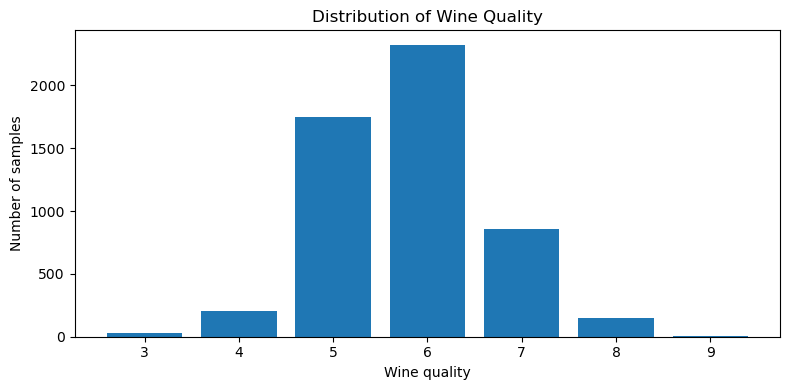

Quality proportions:


,proportion
quality,
3,0.006
4,0.039
5,0.329
6,0.437
7,0.161
8,0.028
9,0.001


In [53]:
# Show summary statistics for the cleaned dataset.
display(wine_clean.describe(include="all").T)

# Look at how common each quality score is.
quality_counts = wine_clean["quality"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(quality_counts.index.astype(str), quality_counts.values)
plt.xlabel("Wine quality")
plt.ylabel("Number of samples")
plt.title("Distribution of Wine Quality")
plt.tight_layout()
plt.show()

print("Quality proportions:")
display((quality_counts / len(wine_clean)).rename("proportion").to_frame())

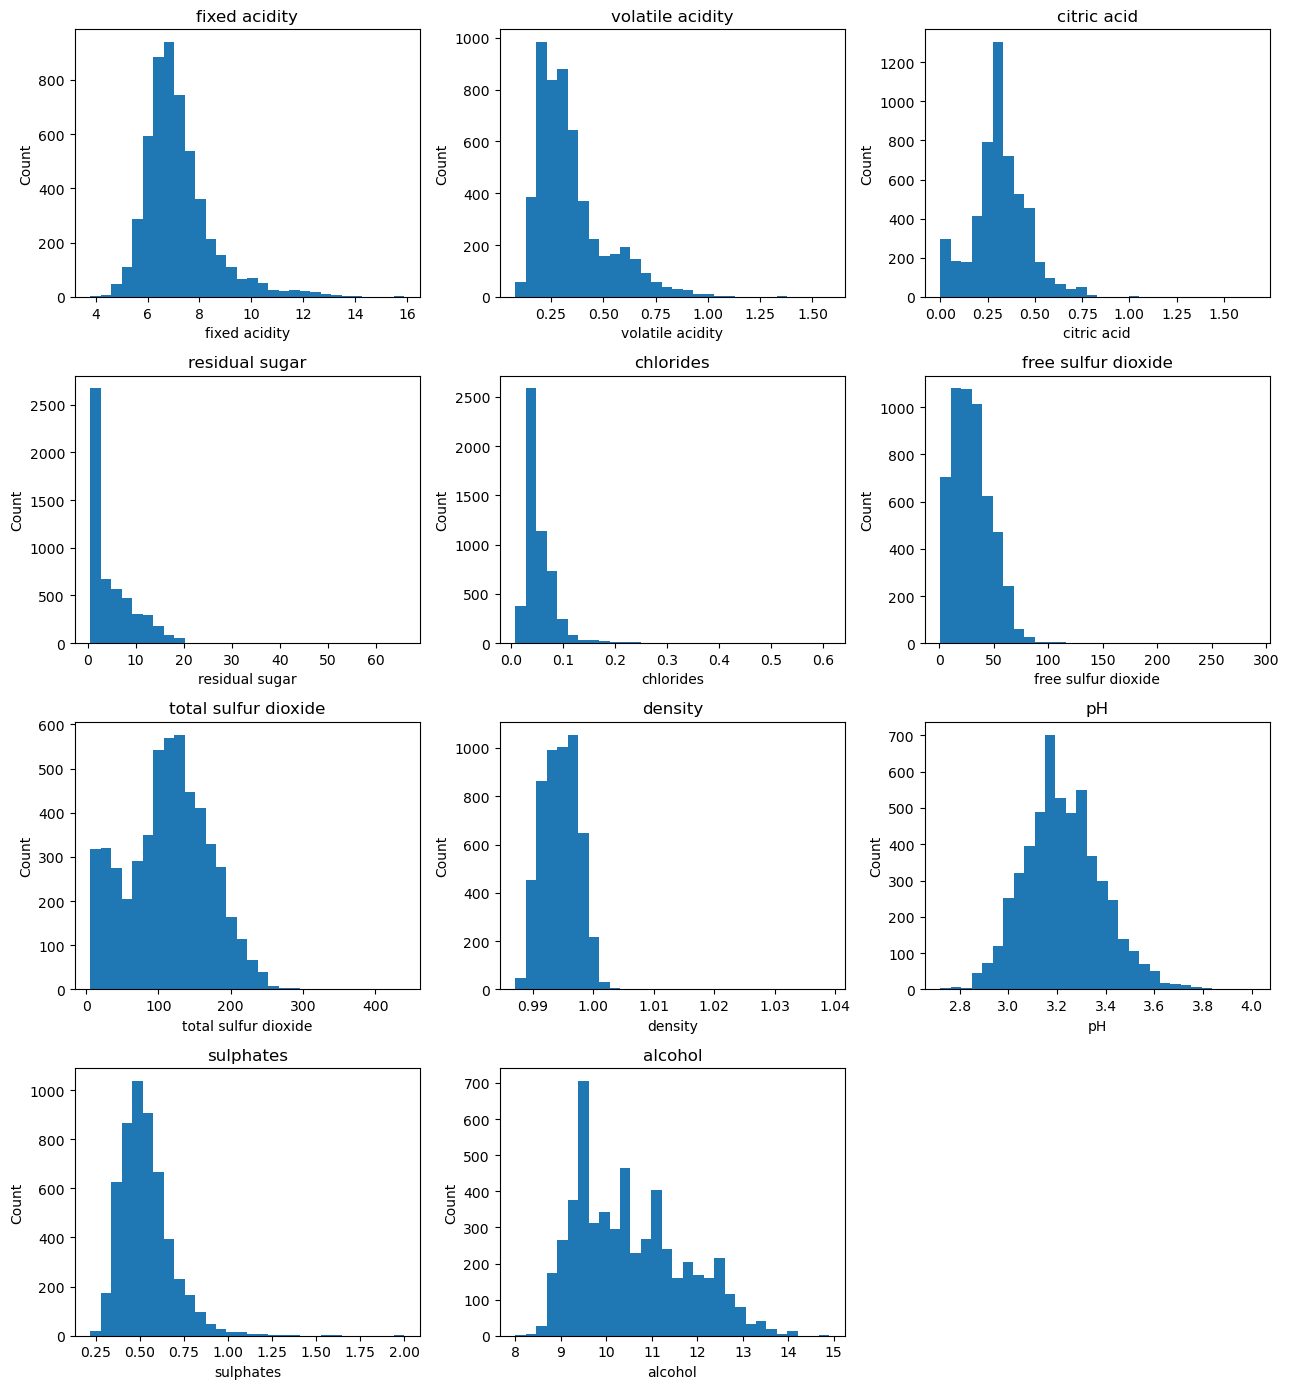

In [54]:
# Plot the distributions of the numeric features.
numeric_features = expected_numeric[:-1]

ncols = 3
nrows = int(np.ceil(len(numeric_features) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(13, 14))
axes = np.array(axes).reshape(-1)

for i, column in enumerate(numeric_features):
    axes[i].hist(wine_clean[column], bins=30)
    axes[i].set_title(column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Count")

for i in range(len(numeric_features), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [55]:
# Find possible outliers using the IQR method.
outlier_rows = []

for column in numeric_features:
    q1 = wine_clean[column].quantile(0.25)
    q3 = wine_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((wine_clean[column] < lower) | (wine_clean[column] > upper)).sum()

    outlier_rows.append({
        "feature": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "outlier_count": int(count),
        "outlier_percent": 100 * count / len(wine_clean)
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("outlier_percent", ascending=False)
display(outlier_report)

,feature,Q1,Q3,IQR,outlier_count,outlier_percent
0,fixed acidity,6.400,7.700,1.300,304,5.714
1,volatile acidity,0.230,0.410,0.180,279,5.244
4,chlorides,0.038,0.066,0.028,237,4.455
9,sulphates,0.430,0.600,0.170,163,3.064
2,citric acid,0.240,0.400,0.160,143,2.688
3,residual sugar,1.800,7.500,5.700,141,2.650
8,pH,3.110,3.330,0.220,49,0.921
5,free sulfur dioxide,16.000,41.000,25.000,44,0.827
6,total sulfur dioxide,74.000,153.250,79.250,10,0.188
7,density,0.992,0.997,0.005,3,0.056


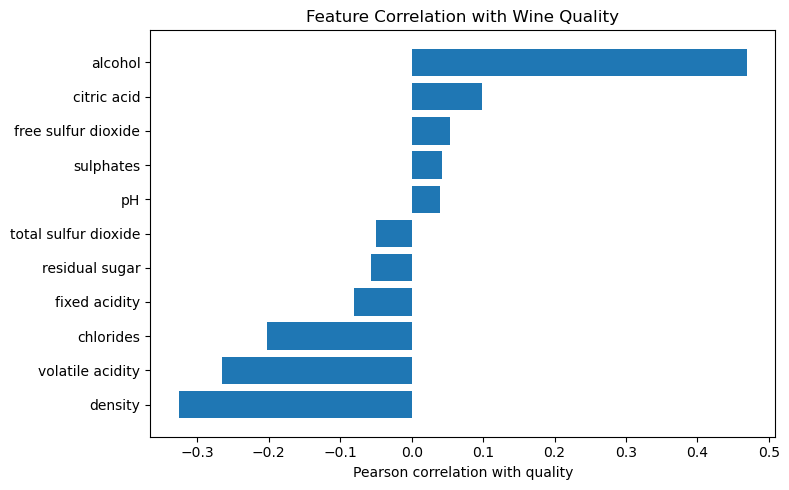

,correlation
density,-0.326
volatile acidity,-0.265
chlorides,-0.202
fixed acidity,-0.080
residual sugar,-0.057
total sulfur dioxide,-0.050
pH,0.040
sulphates,0.042
free sulfur dioxide,0.054
citric acid,0.098


In [56]:
# Check how each numeric feature is related to quality.
correlations = (
    wine_clean[numeric_features + ["quality"]]
    .corr(numeric_only=True)["quality"]
    .drop("quality")
    .sort_values()
)

plt.figure(figsize=(8, 5))
plt.barh(correlations.index, correlations.values)
plt.xlabel("Pearson correlation with quality")
plt.title("Feature Correlation with Wine Quality")
plt.tight_layout()
plt.show()

display(correlations.rename("correlation").to_frame())

Features with the largest change in group means across quality levels:


,range_of_quality_group_means
total sulfur dioxide,20.516
free sulfur dioxide,18.884
alcohol,2.308
residual sugar,1.447
fixed acidity,1.033
volatile acidity,0.225


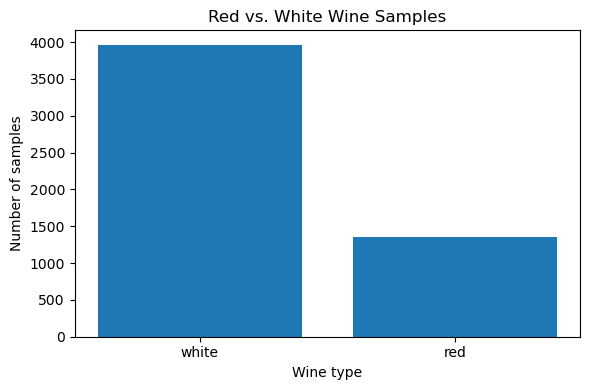

Quality by wine type:


quality,3,4,5,6,7,8,9
wine_type,,,,,,,
red,0.007,0.039,0.425,0.394,0.123,0.013,0.000
white,0.005,0.039,0.297,0.451,0.174,0.033,0.001


In [57]:
# Compare the average feature values for each quality score.
quality_means = wine_clean.groupby("quality")[numeric_features].mean()

# Find the features with the biggest difference between quality groups.
mean_change = (quality_means.max() - quality_means.min()).sort_values(ascending=False)
print("Features with the largest change in group means across quality levels:")
display(mean_change.head(6).rename("range_of_quality_group_means").to_frame())

# Compare the number of red and white wine samples.
type_counts = wine_clean["wine_type"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(type_counts.index, type_counts.values)
plt.xlabel("Wine type")
plt.ylabel("Number of samples")
plt.title("Red vs. White Wine Samples")
plt.tight_layout()
plt.show()

print("Quality by wine type:")
display(pd.crosstab(wine_clean["wine_type"], wine_clean["quality"], normalize="index").round(3))

### EDA Interpretation

Most of the wines have quality scores of 5 or 6, while the lower and higher scores are much less common. Because of this imbalance, accuracy by itself would not give a complete picture of how well the model works. Some of the features also have values that are far from the middle of the distribution. I did not automatically remove these values because an outlier is not necessarily a bad measurement. The correlation results show that alcohol has the strongest positive relationship with quality, while density and volatile acidity have some of the stronger negative relationships. These correlations are useful for getting an idea of the data, but they do not prove that one feature causes a change in quality.

## Feature preparation and supervised-learning targets

I used two different targets for the models. The first one predicts the original wine quality score, which gives a multiclass problem. The second one creates a simpler yes/no prediction for whether the wine should receive additional review.

For the binary target, a quality score of 5 or lower is labeled as review_required = 1. This makes the problem easier to connect to the scenario in the assignment. In this situation, missing a wine that needs review could be more serious than sending an acceptable wine for an extra review.

The preprocessing is kept inside the machine learning pipeline. This means the scaling, imputation, and encoding are learned from the training data instead of using the test data.

In [58]:
# Create the targets used by the models.
model_data = wine_clean.copy()

model_data["review_required"] = (model_data["quality"] <= 5).astype(int)

X = model_data.drop(columns=["quality", "review_required"])
y_multi = model_data["quality"]
y_binary = model_data["review_required"]

feature_columns = X.columns.tolist()

print("Feature columns:")
print(feature_columns)

print("\nMulticlass label counts:")
display(y_multi.value_counts().sort_index().rename("count").to_frame())

print("\nBinary review target:")
display(y_binary.value_counts().sort_index().rename("count").to_frame())

print("\nBinary class proportions:")
display(y_binary.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Feature columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'wine_type']

Multiclass label counts:


,count
quality,
3,30
4,206
5,1752
6,2323
7,856
8,148
9,5



Binary review target:


,count
review_required,
0,3332
1,1988



Binary class proportions:


,proportion
review_required,
0,0.626
1,0.374


In [72]:
# Split the data before checking the training-set feature distributions.
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X, y_multi,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_multi
)

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X, y_binary,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_binary
)

numeric_feature_names = [c for c in feature_columns if c != "wine_type"]

# Check which numeric features are the most skewed.
train_skew = X_train_multi[numeric_feature_names].skew().sort_values(
    key=np.abs,
    ascending=False
)

# Check which numeric features are the most skewed.
train_skew = X_train_multi[numeric_feature_names].skew().sort_values(
    key=np.abs,
    ascending=False
)

print("Training-set skewness:")
display(train_skew.to_frame("skewness"))

print("Features with |skewness| > 1:")
print([c for c in train_skew.index if abs(train_skew[c]) > 1])

Training-set skewness:


,skewness
chlorides,5.090
residual sugar,1.807
fixed acidity,1.680
volatile acidity,1.533
free sulfur dioxide,1.519
sulphates,1.491
density,0.803
alcohol,0.540
citric acid,0.482
pH,0.430


Features with |skewness| > 1:
['chlorides', 'residual sugar', 'fixed acidity', 'volatile acidity', 'free sulfur dioxide', 'sulphates']


In [60]:
# Set up the preprocessing steps for numeric and categorical features.

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_feature_names),
    ("categorical", categorical_pipeline, ["wine_type"])
])

print("Standardized numeric features:", numeric_feature_names)
print("Categorical feature:", ["wine_type"])

Standardized numeric features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Categorical feature: ['wine_type']


## Baseline models

I tested three models because they give different types of baselines for this dataset.

- Logistic Regression: This is a simple linear model and gives a useful starting point.
- Random Forest: This can handle nonlinear relationships and interactions between features.
- HistGradientBoosting: This is another tree-based model that can handle more complicated patterns in the data.

These are baseline models, so the results should not be treated as proof that one of them is ready for production.

In [61]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        random_state=RANDOM_STATE
    )
}

# Put the preprocessing and model together in one pipeline.
def make_pipeline(model):
    return Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

pipelines = {name: make_pipeline(model) for name, model in models.items()}

print("Models:", list(pipelines.keys()))

Models: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']


## Multiclass Modeling and Evaluation

The Random Forest had the best multiclass test result based on macro F1, with a score of 0.287. Its accuracy was 0.561, but the balanced accuracy was only 0.271. This shows why accuracy is not enough for this dataset. The model did reasonably better on the more common quality levels, especially 5 and 6, but it had very poor results for the rare classes. It did not correctly identify any of the quality 3 or quality 9 samples in the test set. The 3-fold cross-validation result was also low, with a macro F1 of about 0.268. Overall, predicting the exact quality score is difficult because some quality levels have very few examples.

In [62]:
multi_results = []
multi_fitted = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train_multi, y_train_multi)
    pred = pipe.predict(X_test_multi)

    multi_fitted[name] = pipe

    multi_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_multi, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test_multi, pred),
        "macro_precision": precision_score(y_test_multi, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test_multi, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test_multi, pred, average="macro", zero_division=0)
    })

multi_results_df = pd.DataFrame(multi_results).sort_values("macro_f1", ascending=False)
display(multi_results_df)

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
1,Random Forest,0.566,0.272,0.428,0.272,0.289
2,HistGradientBoosting,0.555,0.260,0.342,0.260,0.270
0,Logistic Regression,0.329,0.363,0.250,0.363,0.226


In [63]:
# Use 3 folds because the rarest quality class has very few samples.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

cv_multi_rows = []

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe,
        X_train_multi,
        y_train_multi,
        cv=cv,
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=-1
    )

    cv_multi_rows.append({
        "model": name,
        "cv_balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
        "cv_balanced_accuracy_std": scores["test_balanced_accuracy"].std(),
        "cv_macro_f1_mean": scores["test_macro_f1"].mean(),
        "cv_macro_f1_std": scores["test_macro_f1"].std()
    })

cv_multi_df = pd.DataFrame(cv_multi_rows).sort_values(
    "cv_macro_f1_mean",
    ascending=False
)

display(cv_multi_df)

,model,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std
1,Random Forest,0.261,0.003,0.268,0.006
2,HistGradientBoosting,0.248,0.004,0.256,0.005
0,Logistic Regression,0.359,0.081,0.225,0.011


Best multiclass model: Random Forest

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.33      0.07      0.12        41
           5       0.59      0.70      0.64       350
           6       0.56      0.61      0.58       465
           7       0.52      0.39      0.45       171
           8       1.00      0.13      0.24        30
           9       0.00      0.00      0.00         1

    accuracy                           0.57      1064
   macro avg       0.43      0.27      0.29      1064
weighted avg       0.56      0.57      0.55      1064



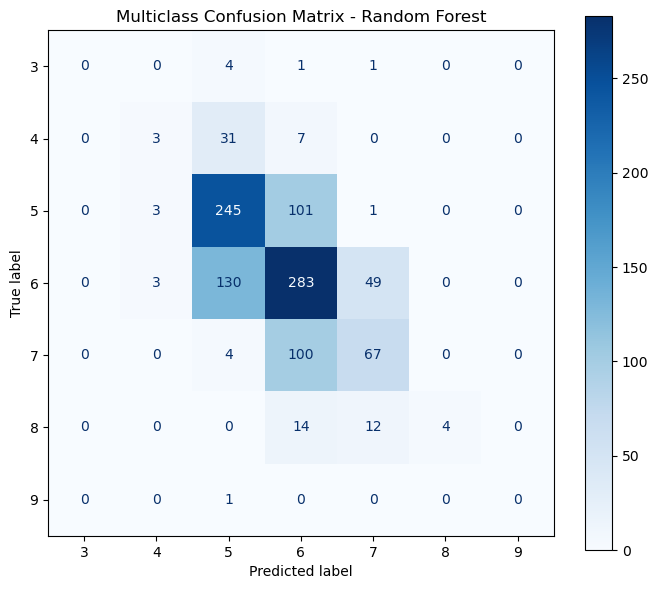

In [64]:
# Detailed report for the best multiclass model.
best_multi_name = multi_results_df.iloc[0]["model"]
best_multi_model = multi_fitted[best_multi_name]
best_multi_pred = best_multi_model.predict(X_test_multi)

print("Best multiclass model:", best_multi_name)
print()
print(classification_report(y_test_multi, best_multi_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    best_multi_pred,
    cmap="Blues",
    ax=ax
)
ax.set_title(f"Multiclass Confusion Matrix - {best_multi_name}")
plt.tight_layout()
plt.show()

## Binary Review Model

# Which samples should recieve additional review?

The binary version of the problem is easier to connect to the scenario. Instead of trying to predict every quality score, the model predicts whether the wine has a quality score of 5 or lower.

Logistic Regression had the best F1 score on the test set at 0.686. Its recall for the review-required class was 0.729, meaning it found about 73% of the samples that were labeled as needing review. Its ROC AUC was 0.818. The 3-fold cross-validation results were similar, with an average F1 of 0.683 and ROC AUC of 0.813. This gives more confidence that the result was not only caused by one train/test split.

In [65]:
binary_results = []
binary_fitted = {}
binary_predictions = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train_bin, y_train_bin)
    pred = pipe.predict(X_test_bin)
    proba = pipe.predict_proba(X_test_bin)[:, 1]

    binary_fitted[name] = pipe
    binary_predictions[name] = (pred, proba)

    binary_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_bin, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test_bin, pred),
        "precision": precision_score(y_test_bin, pred, zero_division=0),
        "recall": recall_score(y_test_bin, pred, zero_division=0),
        "f1": f1_score(y_test_bin, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test_bin, proba),
        "average_precision": average_precision_score(y_test_bin, proba)
    })

binary_results_df = pd.DataFrame(binary_results).sort_values("f1", ascending=False)
display(binary_results_df)

,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
0,Logistic Regression,0.740,0.733,0.637,0.709,0.671,0.813,0.713
1,Random Forest,0.771,0.739,0.729,0.616,0.668,0.841,0.735
2,HistGradientBoosting,0.755,0.722,0.706,0.590,0.643,0.821,0.717


In [66]:
# Compare the models using cross-validation on the training data.
cv_binary_rows = []

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe,
        X_train_bin,
        y_train_bin,
        cv=cv,
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "f1": "f1",
            "roc_auc": "roc_auc",
            "average_precision": "average_precision"
        },
        n_jobs=-1
    )

    cv_binary_rows.append({
        "model": name,
        "cv_balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
        "cv_f1_mean": scores["test_f1"].mean(),
        "cv_roc_auc_mean": scores["test_roc_auc"].mean(),
        "cv_average_precision_mean": scores["test_average_precision"].mean()
    })

cv_binary_df = pd.DataFrame(cv_binary_rows).sort_values(
    "cv_f1_mean",
    ascending=False
)

display(cv_binary_df)

,model,cv_balanced_accuracy_mean,cv_f1_mean,cv_roc_auc_mean,cv_average_precision_mean
0,Logistic Regression,0.739,0.680,0.805,0.694
1,Random Forest,0.743,0.676,0.833,0.730
2,HistGradientBoosting,0.738,0.669,0.825,0.722


Best binary baseline model: Logistic Regression

                 precision    recall  f1-score   support

      No review       0.81      0.76      0.78       666
Review required       0.64      0.71      0.67       398

       accuracy                           0.74      1064
      macro avg       0.72      0.73      0.73      1064
   weighted avg       0.75      0.74      0.74      1064



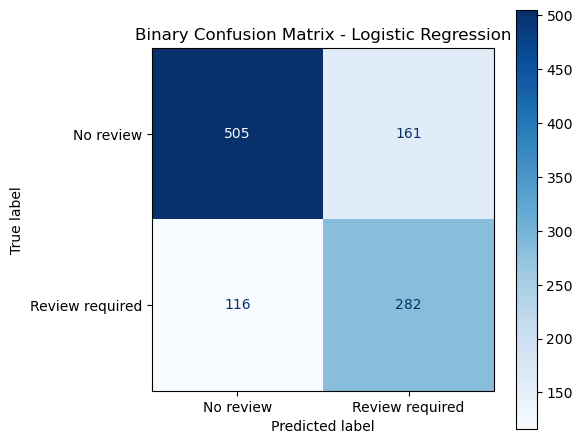

In [67]:
# Select the binary model using F1 as a balanced baseline criterion.
# In a real deployment, the decision threshold should be chosen from business costs,
# not simply from the default 0.50 probability threshold.
best_binary_name = binary_results_df.iloc[0]["model"]
best_binary_model = binary_fitted[best_binary_name]
best_binary_pred, best_binary_proba = binary_predictions[best_binary_name]

print("Best binary baseline model:", best_binary_name)
print()
print(classification_report(
    y_test_bin,
    best_binary_pred,
    target_names=["No review", "Review required"],
    zero_division=0
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_bin,
    best_binary_pred,
    display_labels=["No review", "Review required"],
    cmap="Blues",
    ax=ax
)
ax.set_title(f"Binary Confusion Matrix - {best_binary_name}")
plt.tight_layout()
plt.show()

## Operational Threshold Analysis

The default probability threshold of 0.50 is not necessarily the best choice for this problem. Lowering the threshold causes the model to flag more wines for review and increases recall, but it also creates more false positives.

For example, at a threshold of 0.20, recall increases to 0.947, but about 75% of the test samples would be flagged. At the 0.50 threshold, recall is 0.729 and about 42% of the samples are flagged. A real company would need to decide how much it costs to miss a wine that needs review compared with the cost of reviewing a wine that does not actually need it. The threshold should be chosen using those costs instead of automatically using 0.50.

In [68]:
# See how changing the probability cutoff affects precision and recall.
threshold_rows = []

for threshold in np.arange(0.20, 0.81, 0.05):
    pred_at_threshold = (best_binary_proba >= threshold).astype(int)

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_test_bin, pred_at_threshold, zero_division=0),
        "recall": recall_score(y_test_bin, pred_at_threshold, zero_division=0),
        "f1": f1_score(y_test_bin, pred_at_threshold, zero_division=0),
        "samples_flagged": int(pred_at_threshold.sum()),
        "percent_flagged": 100 * pred_at_threshold.mean()
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)

,threshold,precision,recall,f1,samples_flagged,percent_flagged
0,0.200,0.462,0.957,0.624,824,77.444
1,0.250,0.495,0.922,0.644,741,69.643
2,0.300,0.528,0.887,0.662,669,62.876
3,0.350,0.554,0.854,0.672,614,57.707
4,0.400,0.573,0.822,0.675,571,53.665
5,0.450,0.603,0.774,0.678,511,48.026
6,0.500,0.637,0.709,0.671,443,41.635
7,0.550,0.677,0.653,0.665,384,36.090
8,0.600,0.708,0.590,0.644,332,31.203
9,0.650,0.722,0.510,0.598,281,26.410


## Feature Importance and Model Interpretation

The best binary model was Logistic Regression rather than Random Forest, so the random forest feature-importance plot was not used as the main interpretation for the binary model. The model results are still useful for comparing performance, but a more detailed interpretation of the Logistic Regression coefficients could be added if needed.

In [69]:
# Extract feature names and importances when the selected model is tree-based.
def get_transformed_feature_names(fitted_pipeline):
    prep = fitted_pipeline.named_steps["preprocessing"]
    return prep.get_feature_names_out()

if best_binary_name == "Random Forest":
    feature_names = get_transformed_feature_names(best_binary_model)
    importances = best_binary_model.named_steps["model"].feature_importances_

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(9, 6))
    plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1])
    plt.xlabel("Random forest importance")
    plt.title("Top Predictive Features - Binary Model")
    plt.tight_layout()
    plt.show()
else:
    print(
        f"The selected binary model is {best_binary_name}, "
        "so a random forest feature-importance plot is not shown."
    )

The selected binary model is Logistic Regression, so a random forest feature-importance plot is not shown.


## Data Leakage, Reproducibility, Monitoring, and Drift

### Leakage prevention

I removed quality from the input features before training the models. The binary target is also removed from the inputs. The preprocessing steps are inside the pipeline, so the test data is not used to calculate the scaling or other preprocessing values. I also removed duplicate rows before creating the train and test sets.

### Reproducibility

The notebook uses the same dataset URLs, random seed, preprocessing steps, and model settings each time it is run. For a real system, I would also save the dataset version, package versions, trained pipeline, and feature names so the model could be reproduced later.

### Post-deployment monitoring

If this model were actually used, I would monitor how many wines are being flagged, the false-negative rate, precision, recall, and changes in the input data. Missing values and values outside the expected ranges should also be checked. If actual review results were collected, they could be used to see whether the model is still performing well.

### Potential drift signals

The data could change if the winery changes suppliers, grape varieties, equipment, production methods, or other parts of the process. Changes in features such as alcohol, density, sulfur dioxide, or acidity could be signs of this. The current dataset does not have timestamps or batch IDs, so I cannot test for actual changes over time. A real system should keep this information so that performance and data changes can be checked over time.

## Compact Validation and EDA Summary

In [70]:
# Get the best cross-validation results for the final summary.
best_multi_cv = cv_multi_df.iloc[0]
best_binary_cv = cv_binary_df.iloc[0]

most_skewed_feature = train_skew.abs().idxmax()
highest_outlier_feature = outlier_report.iloc[0]["feature"]

print("VALIDATION REPORT")
print("=" * 70)
print(f"Final sample count after exact-duplicate removal: {len(wine_clean):,}")
print(f"Final feature count before preprocessing: {len(feature_columns):,}")
print(f"Missing values after cleanup: {int(wine_clean.isna().sum().sum()):,}")
print(f"Exact duplicates removed: {removed_duplicates:,}")
print(f"Most skewed numeric feature in the training data: {most_skewed_feature}")
print(f"Feature with the highest IQR-outlier percentage: {highest_outlier_feature}")

print("\nMULTICLASS MODELING")
print("-" * 70)
print(f"Best model by test macro F1: {best_multi_name}")
print(f"Best model 3-fold CV macro F1: {best_multi_cv['cv_macro_f1_mean']:.3f}")
print(f"Best model 3-fold CV balanced accuracy: {best_multi_cv['cv_balanced_accuracy_mean']:.3f}")

print("\nBINARY REVIEW MODEL")
print("-" * 70)
print(f"Best model by test F1: {best_binary_name}")
print(f"Best model 3-fold CV F1: {best_binary_cv['cv_f1_mean']:.3f}")
print(f"Best model 3-fold CV ROC AUC: {best_binary_cv['cv_roc_auc_mean']:.3f}")
print(f"Best model 3-fold CV average precision: {best_binary_cv['cv_average_precision_mean']:.3f}")

print("\nOPERATIONAL INTERPRETATION")
print("-" * 70)
print(
    "The binary task treats quality <= 5 as review-required. "
    "The probability threshold should depend on the cost of missed reviews "
    "versus unnecessary reviews."
)

print("\nLIMITATIONS")
print("-" * 70)
print(
    "The dataset does not include timestamps, production-line information, "
    "or batch IDs, so I cannot test for time-based or batch-based issues."
)

VALIDATION REPORT
Final sample count after exact-duplicate removal: 5,320
Final feature count before preprocessing: 12
Missing values after cleanup: 0
Exact duplicates removed: 1,177
Most skewed numeric feature in the training data: chlorides
Feature with the highest IQR-outlier percentage: fixed acidity

MULTICLASS MODELING
----------------------------------------------------------------------
Best model by test macro F1: Random Forest
Best model 3-fold CV macro F1: 0.268
Best model 3-fold CV balanced accuracy: 0.261

BINARY REVIEW MODEL
----------------------------------------------------------------------
Best model by test F1: Logistic Regression
Best model 3-fold CV F1: 0.680
Best model 3-fold CV ROC AUC: 0.805
Best model 3-fold CV average precision: 0.694

OPERATIONAL INTERPRETATION
----------------------------------------------------------------------
The binary task treats quality <= 5 as review-required. The probability threshold should depend on the cost of missed reviews ver

## Final conclusion

The analysis shows that the wine dataset can be used for a basic machine learning workflow, but there are some important limitations. Most of the quality scores are 5 or 6, while the other classes have fewer samples, which makes the multiclass problem harder. The Random Forest performed best for the multiclass problem, but its performance on the rare quality levels was poor.

The binary problem was more useful for the review scenario. Logistic Regression had the best F1 score and performed fairly consistently in both the test set and cross-validation. The threshold results also showed that changing the threshold can increase recall when finding wines that may need review is more important.

There are still several things that would need to be addressed before using a model like this in a real production system. The dataset does not contain timestamps, batch information, production lines, or actual review outcomes. Because of this, I could not test for temporal drift or determine the real cost of false positives and false negatives. Overall, these results are a useful starting point, but more production data and testing would be needed before using the model to make actual wine release decisions.